# Influence-Based Deletion Evaluation

This experiment is separate from the existing random-deletion evaluation. For each validation query, the deletion-aware checkpoint defines a single leave-one-out influence ranking. The same query-specific nested deletion sets are then evaluated with both checkpoints.

For support set $S$, the classifier's retained SPM fusion output is the gated attention aggregation immediately before the logarithm/classification processing. For each support sample $s_i$,
$$I_i(q) = \lVert z_q(S) - z_q(S \setminus \{s_i\}) \rVert_2.$$

Supports are ranked by descending $I_i(q)$. At fraction $p$, the first $\lfloor p|S| \rfloor$ eligible supports are deleted, while one support per class is preserved. The reported metrics are
$$\Delta(p)=A_{\mathrm{full}}-A_p, \qquad \Delta_{\mathrm{rel}}(p)=\frac{\Delta(p)}{A_{\mathrm{full}}},$$
$$\Delta_{\mathrm{robust}}(p)=\Delta_{\mathrm{normal}}(p)-\Delta_{\mathrm{deletion\text{-}aware}}(p).$$
Positive $\Delta_{\mathrm{robust}}$ means the deletion-aware model degraded less.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

os.chdir('/home/neillucha/SNU/proj/MUL/spm_unlearning')
repo_root = os.getcwd()
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)
from scripts.eval_influence_deletion import evaluate_influence_paired

CONFIG = 'config/classification/cifar_resnet18_deletion.yaml'
DELETION_AWARE_CKPT = 'results/classification/cifar_resnet18_deletion/last.ckpt'
NORMAL_CKPT = 'results/classification/cifar_resnet18/last.ckpt'
OUTPUT_DIR = 'results/eval_influence'
DELETION_PS = [0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9]

In [2]:
# Run both checkpoints on the same sampled validation batches and masks.
results = evaluate_influence_paired(
    CONFIG,
    DELETION_AWARE_CKPT,
    NORMAL_CKPT,
    deletion_ps=DELETION_PS,
    max_batches=200,
    seed=0,
    out_dir=OUTPUT_DIR,
)
print(f"Evaluated {results['n_batches']} batches")

2026-08-21 09:50:11,945 | INFO | Starting influence evaluation: max_batches=200, deletion_ps=[0.0, 0.1, 0.2, 0.4, 0.6, 0.8, 0.9]
2026-08-21 09:50:14,696 | INFO | Loaded checkpoints: deletion-aware=results/classification/cifar_resnet18_deletion/last.ckpt; normal=results/classification/cifar_resnet18/last.ckpt
2026-08-21 09:50:16,724 | INFO | Using device: cuda
2026-08-21 09:50:16,724 | INFO | Validation loader ready: 40 batches available; processing up to 40
2026-08-21 09:50:17,960 | INFO | Batch 1/40 started: 256 queries, 4096 supports; leave-one-out ranking in progress
2026-08-21 09:50:37,705 | INFO | Batch 1/40 complete in 17.4s; elapsed=23s
2026-08-21 09:50:37,713 | INFO | Batch 2/40 started: 256 queries, 4096 supports; leave-one-out ranking in progress
2026-08-21 09:50:52,821 | INFO | Batch 2/40 complete in 15.1s; elapsed=38s
2026-08-21 09:50:52,829 | INFO | Batch 3/40 started: 256 queries, 4096 supports; leave-one-out ranking in progress
2026-08-21 09:51:11,427 | INFO | Batch 3/40

Evaluated 40 batches


In [3]:
def metric_row(record, model_key, metric_key):
    metric = record[model_key][metric_key]
    return {'p': record['p'], 'model': model_key, 'metric': metric_key, **metric}

rows = []
for record in results['summary']:
    for model_key in ['deletion_aware', 'normal']:
        for metric_key in ['Afull', 'A_p', 'Delta', 'Delta_rel', 'fusion_l2']:
            rows.append(metric_row(record, model_key, metric_key))
    robust = record['Delta_robust']
    rows.append({'p': record['p'], 'model': 'comparison', 'metric': 'Delta_robust', **robust})
summary_df = pd.DataFrame(rows)
display(summary_df[['p', 'model', 'metric', 'mean', 'std', 'stderr']])

,p,model,metric,mean,std,stderr
0,0.0,deletion_aware,Afull,0.936800,0.243335,0.002433
1,0.0,deletion_aware,A_p,0.936800,0.243335,0.002433
2,0.0,deletion_aware,Delta,0.000000,0.000000,0.000000
3,0.0,deletion_aware,Delta_rel,0.000000,0.000000,0.000000
4,0.0,deletion_aware,fusion_l2,0.000000,0.000000,0.000000
...,...,...,...,...,...,...
72,0.9,normal,A_p,0.941200,0.235262,0.002353
73,0.9,normal,Delta,0.001800,0.078723,0.000787
74,0.9,normal,Delta_rel,0.004242,0.064994,0.000669
75,0.9,normal,fusion_l2,0.011965,0.050622,0.000506


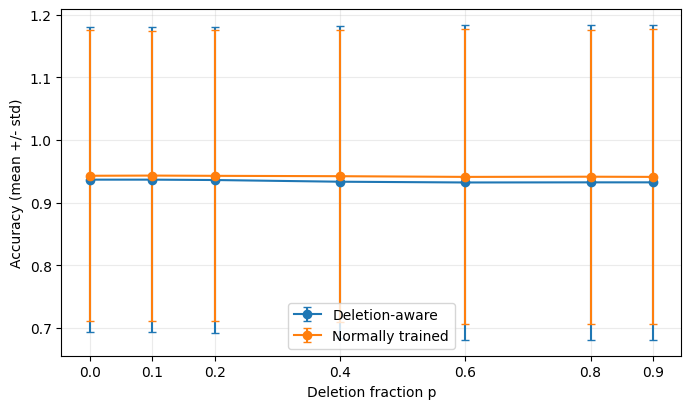

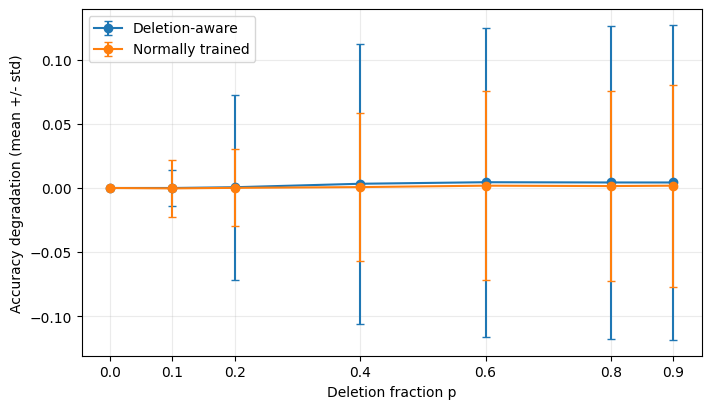

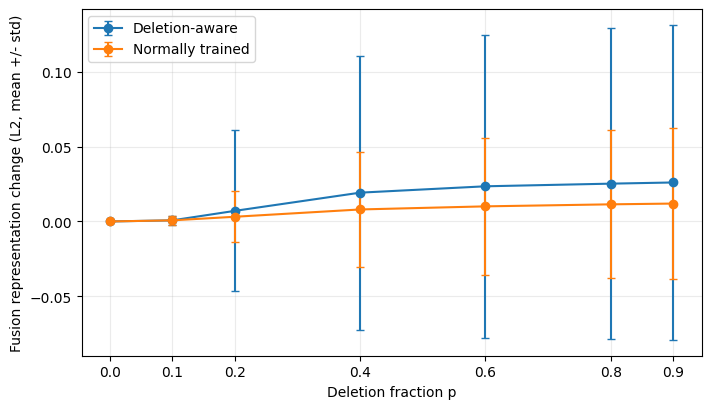

In [4]:
def plot_metric(metric, ylabel):
    figure, axis = plt.subplots(figsize=(8, 4.5))
    for model_key, label, color in [
        ('deletion_aware', 'Deletion-aware', 'tab:blue'),
        ('normal', 'Normally trained', 'tab:orange'),
    ]:
        data = summary_df[(summary_df.model == model_key) & (summary_df.metric == metric)]
        axis.errorbar(data.p, data['mean'], yerr=data['std'], marker='o', capsize=3, label=label, color=color)
    axis.set_xlabel('Deletion fraction p')
    axis.set_ylabel(ylabel)
    axis.set_xticks(DELETION_PS)
    axis.grid(alpha=0.25)
    axis.legend()
    plt.show()

plot_metric('A_p', 'Accuracy (mean +/- std)')
plot_metric('Delta', 'Accuracy degradation (mean +/- std)')
plot_metric('fusion_l2', 'Fusion representation change (L2, mean +/- std)')

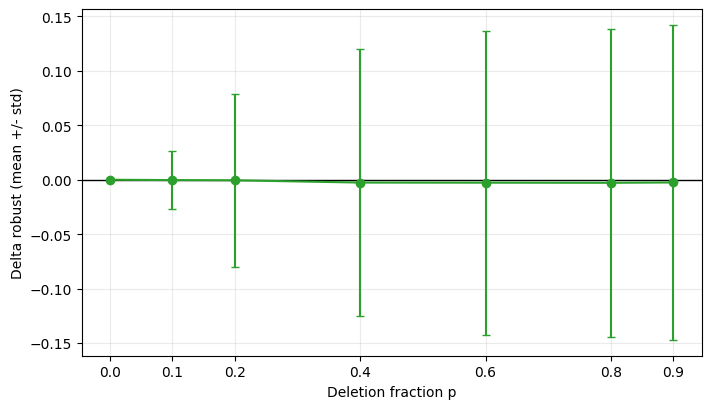

In [5]:
robust_df = summary_df[(summary_df.model == 'comparison') & (summary_df.metric == 'Delta_robust')]
figure, axis = plt.subplots(figsize=(8, 4.5))
axis.errorbar(robust_df.p, robust_df['mean'], yerr=robust_df['std'], marker='o', capsize=3, color='tab:green')
axis.axhline(0.0, color='black', linewidth=1)
axis.set_xlabel('Deletion fraction p')
axis.set_ylabel('Delta robust (mean +/- std)')
axis.set_xticks(DELETION_PS)
axis.grid(alpha=0.25)
plt.show()

## Reproducibility notes

The evaluator samples each validation batch once, deterministically reorders its support set from the supplied seed, computes the influence ranking once per query, and reuses each prefix for both checkpoints. The JSON file also stores every ranking and deletion set, making the pairing auditable. `max_batches` can be reduced for a quick smoke run.